# Module 2 – Target and train / validation / test split

From `games_clean` and `reviews_clean` (Module 1):
1. compute, for each game, the number of reviews and the share of positive reviews during its **first year**;
2. split the games **by release date**: 70% train, 15% validation, 15% test;
3. define **success** with a threshold computed **on the train set only**;
4. look at the target distribution per split and over time.

Output file: `target.parquet` (`app_id`, `release_date`, `n_reviews_1y`, `pos_ratio_1y`, `success`, `split`), used by Modules 3 and 4.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config import *

games = pd.read_parquet(PROC_DIR / "games_clean.parquet", columns=["app_id", "release_date"])
reviews = pd.read_parquet(PROC_DIR / "reviews_clean.parquet", columns=["app_id", "date", "days", "is_recommended"])
print("Games:", len(games), "| Reviews:", len(reviews))

# Check Module 1's `days` instead of assuming it: recompute it from the dates
release = reviews["app_id"].map(games.set_index("app_id")["release_date"])
assert ((reviews["date"] - release).dt.days == reviews["days"]).all(), "`days` does not match the dates"

Games: 10000 | Reviews: 6833248


## 1. Keep the games with a full year of reviews

To measure success after one year, the whole first year must have been observed. A game released less than one year before the last review of the dataset would have an incomplete year, hence fewer reviews. It would wrongly be counted as a failure.

In [2]:
last_review = reviews["date"].max()
full_year = games["release_date"] + pd.Timedelta(days=HORIZON_DAYS) <= last_review

print("Last review of the dataset:", last_review.date())
print("Games without a full year of reviews (removed):", (~full_year).sum())
games = games[full_year]

Last review of the dataset: 2022-12-31
Games without a full year of reviews (removed): 0


Our games were released between 2015 and 2021, and the reviews go up to 2022-12-31: all of them have a full year, none is removed. The check stays useful if the game subset changes (e.g. with games from 2022).

## 2. Number of reviews and share of positive reviews in the first year

Only the reviews posted during the first year are kept: `0 <= days < 365`. Reviews with `days < 0` (early access) were already removed in Module 1.

We start from **all the games** with a `left` join: a game with no review at all keeps `n_reviews_1y = 0`. Starting from the reviews would make these games disappear: we would only keep games that received at least one review, and overestimate the success rate (**survivorship bias**). Their `pos_ratio_1y` stays empty: without reviews, the share of positive reviews does not exist.

The computation is written as a small function, so that it can first be tested on a toy example where the expected answer is known.

In [3]:
def first_year_counts(games, reviews):
    year1 = reviews[reviews["days"] < HORIZON_DAYS]
    assert year1["days"].between(0, HORIZON_DAYS - 1).all()  # no review outside the first year

    counts = year1.groupby("app_id").agg(
        n_reviews_1y=("is_recommended", "size"),  # number of reviews
        pos_ratio_1y=("is_recommended", "mean"),  # mean of True/False = share of positive reviews
    )
    target = games.merge(counts, on="app_id", how="left")  # left: games without reviews are kept
    target["n_reviews_1y"] = target["n_reviews_1y"].fillna(0).astype(int)
    return target

### Test on a toy example

Hand-made data where the answer is known: game 1 has reviews on day 0 (included), day 10, day 364 (last day, included) and day 365 (excluded); game 2 has one review; game 3 has none. This checks the window boundaries (`<` vs `<=`) and that a game without reviews is kept with an unknown ratio.

In [4]:
toy_games = pd.DataFrame({"app_id": [1, 2, 3]})
toy_reviews = pd.DataFrame({
    "app_id":         [1, 1, 1, 1, 2],
    "days":           [0, 10, 364, 365, 4],
    "is_recommended": [True, False, True, True, True],
})
toy = first_year_counts(toy_games, toy_reviews).set_index("app_id")

assert toy.loc[1, "n_reviews_1y"] == 3 and np.isclose(toy.loc[1, "pos_ratio_1y"], 2 / 3)  # day 365 not counted
assert toy.loc[2, "n_reviews_1y"] == 1 and toy.loc[2, "pos_ratio_1y"] == 1
assert toy.loc[3, "n_reviews_1y"] == 0 and np.isnan(toy.loc[3, "pos_ratio_1y"])  # kept, ratio unknown
print("Toy test passed")

Toy test passed


In [5]:
target = first_year_counts(games, reviews)

print("Games with no review in the first year:", (target["n_reviews_1y"] == 0).sum())
target["n_reviews_1y"].describe()

Games with no review in the first year: 2200


count    10000.0000
mean       271.8203
std       2191.8992
min          0.0000
25%          2.0000
50%         12.0000
75%         46.0000
max      71110.0000
Name: n_reviews_1y, dtype: float64

## 3. Split by release date

The games are **not** shuffled at random (`train_test_split`). The model must predict the success of **future** games from **past** games: we train on the oldest games and evaluate on the most recent ones. A random split would put 2021 games in the train set and 2016 games in the test set. The model would then see "the future" (trends, new categories) and its score would be too optimistic.

We cut **on the dates** themselves: the date that separates the oldest 70% of the games (end of train), then the one at 85% (end of validation). All games released on the same day therefore fall in the **same** split. The temporary split of Modules 3 and 4 cut on the rank of the games: the 8 games released on 2020-05-20 were split between train and validation.

In [6]:
d_train = target["release_date"].quantile(SPLIT[0])           # 70% of the games are released before this date
d_val = target["release_date"].quantile(SPLIT[0] + SPLIT[1])  # 85% of the games are released before this date

target["split"] = np.where(target["release_date"] <= d_train, "train",
                  np.where(target["release_date"] <= d_val, "val", "test"))

# No overlap: each split starts after the end of the previous one
dates = target.groupby("split")["release_date"]
assert dates.max()["train"] < dates.min()["val"] and dates.max()["val"] < dates.min()["test"]

print("End of train:", d_train.date(), "| end of validation:", d_val.date())
dates.agg(["count", "min", "max"]).loc[["train", "val", "test"]]

End of train: 2020-05-20 | end of validation: 2021-03-29


,count,min,max
split,,,
train,7007,2015-01-01,2020-05-20
val,1499,2020-05-21,2021-03-29
test,1494,2021-03-30,2021-12-31


## 4. Definition of success

A game is a **success** if it is in the **top 20%** for the number of reviews in its first year **and** has **at least 80%** positive reviews:
- the number of reviews measures **popularity** (it is linked to the number of players);
- the share of positive reviews measures **satisfaction**. A game that is played a lot but disliked is not a success.

The top 20% threshold is the 80th percentile of `n_reviews_1y` **computed on the train set only**, then applied as is to validation and test. Computing it on all the games would be **data leakage**: the number of reviews of the validation and test games would influence the definition of the target.

A relative threshold (top 20%) rather than a fixed number of reviews: the number of reviews depends a lot on the period and on the sample, whereas "being among the most reviewed games" keeps the same meaning.

In [7]:
threshold = target.loc[target["split"] == "train", "n_reviews_1y"].quantile(TOP_QUANTILE)  # TRAIN only
target["success"] = (target["n_reviews_1y"] >= threshold) & (target["pos_ratio_1y"] >= MIN_POS_RATIO)

print("Threshold (80th percentile of train):", threshold, "reviews in the first year")

Threshold (80th percentile of train): 66.0 reviews in the first year


A game without reviews has an empty `pos_ratio_1y`: the comparison `>= 0.8` gives False, so it is not a success.

How many train games meet each condition?

In [8]:
train = target[target["split"] == "train"]
pd.crosstab(train["n_reviews_1y"] >= threshold, train["pos_ratio_1y"] >= MIN_POS_RATIO,
            rownames=["top 20% in reviews"], colnames=["≥ 80% positive"], margins=True)

≥ 80% positive,False,True,All
top 20% in reviews,,,
False,3493,2107,5600
True,483,924,1407
All,3976,3031,7007


**Reading:** in the train set, 1,407 games (20.1%) are in the top 20% for the number of reviews. Among them, 924 also have at least 80% positive reviews: these are the successes. The other 483 are popular but too criticised. The satisfaction condition therefore removes about a third of the popular games.

### What if the threshold were computed on all the games?

To show why the threshold must come from the train set only, we compute it on purpose on all the games (train + validation + test), as a leaky version.

In [9]:
threshold_all = target["n_reviews_1y"].quantile(TOP_QUANTILE)  # WRONG on purpose: uses the val and test games
success_all = (target["n_reviews_1y"] >= threshold_all) & (target["pos_ratio_1y"] >= MIN_POS_RATIO)

print("Threshold on the train set:", threshold, "| on all the games (leaky):", threshold_all)
print("Games whose label changes:", (success_all != target["success"]).sum())

Threshold on the train set: 66.0 | on all the games (leaky): 69.0
Games whose label changes: 36


**Reading:** on all the games, the threshold goes from 66 to 69 reviews and 36 games change label. The difference is small here, but the principle matters: with the leaky threshold, the label of a **training** game would depend on the number of reviews of **future** games (validation and test). The model would be trained on a target that uses information it cannot have.

## 5. Target distribution

The success rate of each split is a proportion measured on a sample of games, so it comes with a **95% confidence interval**. We use the **Wilson** interval rather than the usual `p ± 1.96 × sqrt(p(1 − p) / n)`: it stays inside [0, 1] and remains reliable when the proportion is small (here about 14%) or the split is small.

In [10]:
def wilson_ci(k, n, z=1.96):
    # 95% Wilson confidence interval of a proportion k / n
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

summary = target.groupby("split")["success"].agg(n_games="size", n_successes="sum", rate="mean")
summary = summary.loc[["train", "val", "test"]]
summary["ci95_low"], summary["ci95_high"] = wilson_ci(summary["n_successes"], summary["n_games"])
summary.round(3)

,n_games,n_successes,rate,ci95_low,ci95_high
split,,,,,
train,7007,924,0.132,0.124,0.140
val,1499,235,0.157,0.139,0.176
test,1494,222,0.149,0.131,0.168


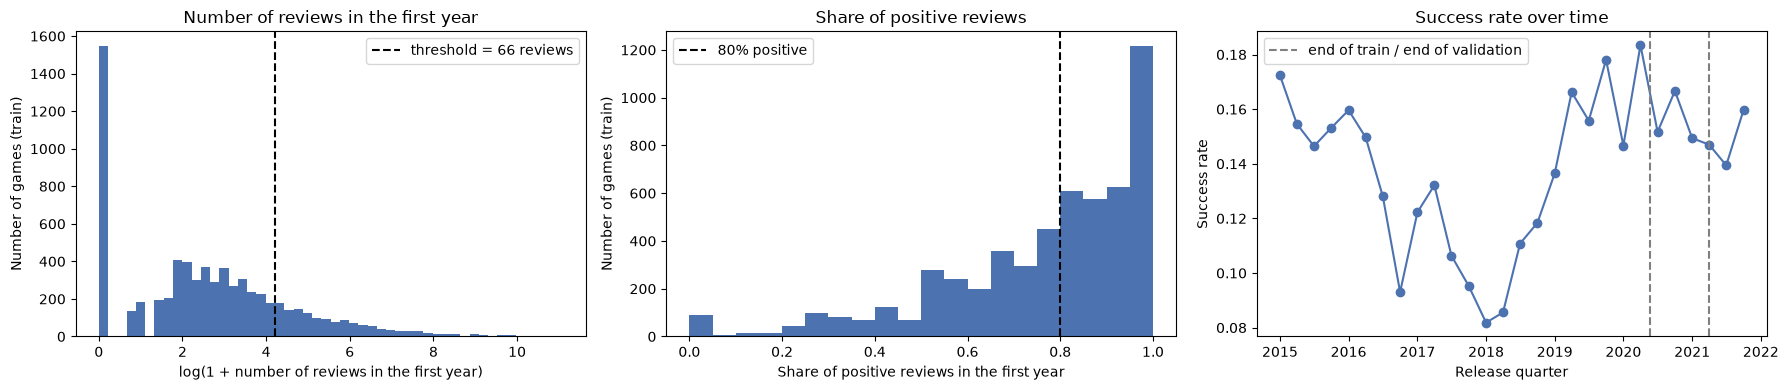

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Number of reviews in the first year (log scale), with the top 20% threshold
axes[0].hist(np.log1p(train["n_reviews_1y"]), bins=50, color="#4C72B0")
axes[0].axvline(np.log1p(threshold), color="black", linestyle="--", label=f"threshold = {threshold:.0f} reviews")
axes[0].set_xlabel("log(1 + number of reviews in the first year)")
axes[0].set_ylabel("Number of games (train)")
axes[0].set_title("Number of reviews in the first year")
axes[0].legend()

# Share of positive reviews in the first year (games with at least one review), with the 80% condition
axes[1].hist(train["pos_ratio_1y"].dropna(), bins=20, color="#4C72B0")
axes[1].axvline(MIN_POS_RATIO, color="black", linestyle="--", label=f"{MIN_POS_RATIO:.0%} positive")
axes[1].set_xlabel("Share of positive reviews in the first year")
axes[1].set_ylabel("Number of games (train)")
axes[1].set_title("Share of positive reviews")
axes[1].legend()

# Success rate per release quarter, with the split boundaries
by_quarter = target.groupby(target["release_date"].dt.to_period("Q"))["success"].mean()
axes[2].plot(by_quarter.index.to_timestamp(), by_quarter.values, marker="o", color="#4C72B0")
axes[2].axvline(d_train, color="gray", linestyle="--", label="end of train / end of validation")
axes[2].axvline(d_val, color="gray", linestyle="--")
axes[2].set_xlabel("Release quarter")
axes[2].set_ylabel("Success rate")
axes[2].set_title("Success rate over time")
axes[2].legend()

plt.tight_layout()
plt.show()

**Reading:**
- **Imbalanced classes:** about 1 game out of 7 is a success (13.2% in the train set). Accuracy is therefore misleading: a model that always answers "failure" would get about 87% accuracy on the train set. The main metric is the PR-AUC, and Module 4 uses `class_weight="balanced"`.
- **22% of the games have no review in their first year** (2,200 games, the large bar at 0 in the histogram). They are kept as failures, which avoids the survivorship bias.
- **The share of positive reviews is high for most games** (train games with at least one review: median 82%, 55.5% of them at 80% or more). The peaks at 100% (15.9% of the games) and at 0% (1.6%) come from games with very few reviews. The 80% condition therefore mainly removes the popular games that are criticised.
- **The number of reviews is very skewed** (`describe()` on all games): median of 12 reviews, mean of 272, maximum of 71,110. A few very popular games pull the mean up. The threshold of 66 reviews is therefore low in absolute terms: about 66 reviews in the first year are enough to be in the top 20% of our sample.
- **The success rate changes over time:** around 15-17% in 2015, it drops to 8-13% from late 2016 to 2018, then rises again to 15-18% from mid-2019. Validation (15.7%, 95% CI [13.9; 17.6]) and test (14.9%, [13.2; 16.8]) therefore have more successes than train (13.2%, [12.4; 14.0]); the train and validation intervals barely overlap, so the gap is not just noise. This is a **distribution shift**. One hypothesis: the massive arrival of small games on Steam from 2017 (opening of Steam Direct) lowered the share of successes. Consequences:
  - the PR-AUC of a random model equals the share of successes: it is not the same in validation and in test, so a model is always compared with the baseline **of the same split**;
  - a model trained on years where successes are rare may underestimate the probabilities on more recent years.

## 6. Saving

In [12]:
target = target[["app_id", "release_date", "n_reviews_1y", "pos_ratio_1y", "success", "split"]]
assert target["app_id"].is_unique

target.to_parquet(PROC_DIR / "target.parquet", index=False)
print("Saved: target.parquet", target.shape)

Saved: target.parquet (10000, 6)


**For Modules 3 and 4:** replace the temporary split and target with a read of `target.parquet`, so that the whole project uses exactly the same split and the same threshold.

**Slot 3 (to come):** class imbalance (`class_weight` compared with resampling **inside** the pipeline), 95% bootstrap confidence intervals of the **model scores** on the validation set (the intervals of the success rates are done above), and a paired test to compare two models.